# Лабораторная работа 1. Анализ высоты и ширины рукописного написания a

Дополнительное задание

Выполнили:  
Янковская Катерина  
Шерстнев Игорь

## Содержание

- [Данные](#data)
- [Анализ независимости величин](#independence)
- [EDA](#eda)
- [Вывод](#conclusion)
- [Источники](#sources)

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import hashlib
import json
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Image

DATA = next((parent / 'data' for parent in [Path.cwd(), *Path.cwd().parents]
             if (parent / 'data/glyphs.csv').is_file()), None)
if DATA is None:
    raise FileNotFoundError('The data directory must accompany this notebook.')
_workspace = TemporaryDirectory(prefix='lab1extra-')
HERE = Path(_workspace.name)
(HERE / 'figures').mkdir()
SEED = 20261111
PERMUTATIONS = 19999
BOOTSTRAPS = 10000
COLORS = {'UJI': '#245B78', 'UPV': '#B87532'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#243447', 'text.color': '#243447',
    'axes.edgecolor': '#C7D3DD', 'grid.color': '#DEE6ED',
    'axes.grid': True, 'grid.alpha': .6, 'legend.frameon': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white'})
pd.set_option('display.max_colwidth', None)


def summary(values):
    x = np.asarray(values, dtype=float)
    if x.ndim != 1 or len(x) < 2 or not np.isfinite(x).all():
        raise ValueError('At least two finite observations are required.')
    unique, counts = np.unique(x, return_counts=True)
    frequency = int(counts.max())
    q05, q25, q50, q75, q95 = np.quantile(x, [.05, .25, .50, .75, .95], method='linear')
    return {'n': len(x), 'sum': float(x.sum()), 'mean': float(x.mean()),
            'median': float(q50), 'min': float(x.min()), 'max': float(x.max()),
            'std': float(x.std(ddof=1)), 'variance': float(x.var(ddof=1)),
            'q05': float(q05), 'q25': float(q25), 'q75': float(q75), 'q95': float(q95),
            'iqr': float(q75-q25), 'mode_frequency': frequency,
            'modes': unique[counts == frequency].tolist() if frequency > 1 else []}


def centered_ranks(x, groups):
    ranks = stats.rankdata(np.asarray(x, dtype=float), method='average')
    labels = np.asarray(groups)
    for group in np.unique(labels):
        positions = labels == group
        ranks[positions] -= ranks[positions].mean()
    return ranks


def adjusted_rank_correlation(x, y, groups):
    """Spearman rank residual correlation after controlling the site indicator."""
    rx, ry = centered_ranks(x, groups), centered_ranks(y, groups)
    denominator = np.linalg.norm(rx) * np.linalg.norm(ry)
    if denominator == 0:
        return float('nan')
    return float(np.dot(rx, ry) / denominator)


def dependence(x, y, groups, permutations=PERMUTATIONS, bootstraps=BOOTSTRAPS, seed=SEED):
    x, y, groups = np.asarray(x), np.asarray(y), np.asarray(groups)
    if len(x) != len(y) or len(y) != len(groups) or not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError('Measurements and groups must be aligned and finite.')
    blocks = [np.flatnonzero(groups == group) for group in np.unique(groups)]
    if any(len(block) < 3 for block in blocks):
        raise ValueError('Each site must contain at least three writers.')
    observed = adjusted_rank_correlation(x, y, groups)
    if not np.isfinite(observed):
        raise ValueError('Association is undefined when residual ranks have zero variance.')
    rng_perm, rng_boot = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(2)]
    rx, ry = centered_ranks(x, groups), centered_ranks(y, groups)
    denominator = np.linalg.norm(rx) * np.linalg.norm(ry)
    null = np.empty(permutations)
    for b in range(permutations):
        shuffled = ry.copy()
        for block in blocks:
            shuffled[block] = rng_perm.permutation(ry[block])
        null[b] = np.dot(rx, shuffled) / denominator
    # Include exact ties; the tolerance only covers floating point rank arithmetic.
    extreme = int(np.count_nonzero(np.abs(null) >= abs(observed) - 1e-12))
    p_mc = (extreme + 1) / (permutations + 1)
    boot = np.empty(bootstraps)
    for b in range(bootstraps):
        selected = np.concatenate([rng_boot.choice(block, len(block), replace=True) for block in blocks])
        boot[b] = adjusted_rank_correlation(x[selected], y[selected], groups[selected])
    valid = boot[np.isfinite(boot)]
    if len(valid) < .99 * bootstraps:
        raise ValueError('Too many undefined bootstrap correlations; review the data.')
    interval = np.quantile(valid, [.025, .975], method='linear')
    info = {'adjusted_rank_correlation': observed, 'permutation_p_two_sided': float(p_mc),
            'permutation_extreme_count': extreme, 'permutations': permutations,
            'permutation_mc_se': float(np.sqrt(p_mc * (1-p_mc)/(permutations+1))),
            'bootstrap_ci95': interval.tolist(), 'bootstraps': bootstraps,
            'valid_bootstraps': len(valid), 'seed': seed, 'alpha': .05,
            'reject_conditional_pairing_null': bool(p_mc < .05)}
    return info, null, valid


def number(value, digits=3):
    return f'{value:.{digits}f}'.replace('.', ',')


def statistic_rows(result, level):
    rows = []
    definitions = [('n', 'Объём, ' + ('записей' if level == 'glyphs' else 'авторов')),
                   ('sum', 'Сумма, мм'), ('mean', 'Среднее, мм'), ('median', 'Медиана, мм'),
                   ('min', 'Минимум, мм'), ('max', 'Максимум, мм'), ('std', 'Стандартное отклонение, мм'),
                   ('variance', 'Выборочная дисперсия, мм²'), ('q05', '5-й перцентиль, мм'),
                   ('q25', '1-й квартиль, мм'), ('q75', '3-й квартиль, мм'),
                   ('q95', '95-й перцентиль, мм'), ('iqr', 'Квартильный размах, мм'), ('modes', 'Все моды, мм')]
    for key, label in definitions:
        values = []
        for col in ['width_mm', 'height_mm']:
            data = result['summaries'][level][col]
            if key == 'n':
                text = str(data[key])
            elif key == 'modes':
                text = '; '.join(number(v) for v in data[key]) if data[key] else 'Нет повторяющихся значений'
            else:
                text = number(data[key])
            values.append(text)
        rows.append([label, *values])
    return rows


raw = pd.read_csv(DATA / 'glyphs.csv', float_precision='round_trip')
assert len(raw) == 120 and raw.writer_id.nunique() == 60
assert raw.groupby('writer_id').size().eq(2).all() and raw.sample_id.is_unique
assert not raw[['height_mm', 'width_mm']].isna().any().any()
assert raw[['height_mm', 'width_mm']].gt(0).all().all()
np.testing.assert_allclose(raw.height_mm, (raw.y_max_ink-raw.y_min_ink)/raw.ink_units_per_mm, rtol=0, atol=1e-12)
np.testing.assert_allclose(raw.width_mm, (raw.x_max_ink-raw.x_min_ink)/raw.ink_units_per_mm, rtol=0, atol=1e-12)
bounds = {}
keep = np.ones(len(raw), dtype=bool)
for column in ('height_mm', 'width_mm'):
    q1, q3 = np.quantile(raw[column], [.25, .75], method='linear')
    iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    within = raw[column].between(lower, upper, inclusive='both').to_numpy()
    bounds[column] = {'q1': float(q1), 'q3': float(q3), 'iqr': float(iqr),
                      'lower': float(lower), 'upper': float(upper), 'outside': int((~within).sum())}
    keep &= within
glyphs = raw.loc[keep].copy()
removed = raw.loc[~keep].copy()
saved_cleaned = pd.read_csv(DATA / 'cleaned_glyphs.csv', float_precision='round_trip')
pd.testing.assert_frame_equal(saved_cleaned, glyphs.reset_index(drop=True), check_exact=True)
writers = glyphs.groupby(['writer_id', 'site'], as_index=False).agg(
    height_mean_mm=('height_mm', 'mean'), width_mean_mm=('width_mm', 'mean'),
    n_reps=('sample_id', 'size'))
groups = writers.site.astype(str) + ':' + writers.n_reps.astype(str)
association, null_correlations, bootstrap_correlations = dependence(
    writers.height_mean_mm.to_numpy(), writers.width_mean_mm.to_numpy(), groups.to_numpy())
result = {'raw_n': len(raw), 'n': len(glyphs), 'removed_n': len(removed),
          'bounds': bounds, 'removed_sample_ids': removed.sample_id.tolist(),
          'writer_n': len(writers), 'writer_blocks': groups.value_counts().to_dict(),
          'summaries': {'glyphs': {'height_mm': summary(glyphs.height_mm), 'width_mm': summary(glyphs.width_mm)}},
          'association': association}
ols_slope, ols_intercept = [float(x) for x in np.polyfit(glyphs.height_mm, glyphs.width_mm, 1)]
result['ols_descriptive'] = {'slope': ols_slope, 'intercept': ols_intercept}
permutation = np.random.default_rng(40).permutation(len(glyphs))
permuted = glyphs.iloc[permutation].reset_index(drop=True)
sample_sizes = np.arange(1, len(glyphs)+1)
cumulative = {column: np.cumsum(permuted[column].to_numpy())/sample_sizes
              for column in ('height_mm', 'width_mm')}
complete_means = {column: float(glyphs[column].mean()) for column in ('height_mm', 'width_mm')}
ordered = glyphs.sort_values(['width_mm', 'writer_id', 'repetition'], kind='mergesort').reset_index(drop=True)



def finish_figure(fig, filename):
    target = HERE / 'figures' / filename
    fig.savefig(target, dpi=150, bbox_inches='tight', facecolor='white', metadata={'Software': 'Matplotlib'})
    plt.close(fig)
    display(Image(filename=str(target)))


def plot_cumulative(column, label, filename):
    fig, ax = plt.subplots(figsize=(9, 4.1), constrained_layout=True)
    line, = ax.plot(sample_sizes, cumulative[column], color=COLORS['UJI'], linewidth=1.5,
                    label='Среднее первых n записей')
    reference = ax.axhline(complete_means[column], color=COLORS['UPV'], linestyle='--', linewidth=1.4,
        label='Среднее всех ' + str(len(glyphs)) + ' записей: ' + number(complete_means[column]) + ' мм')
    ax.scatter([sample_sizes[-1]], [cumulative[column][-1]], color=COLORS['UJI'], s=24, zorder=3)
    ax.set(title=label + ': накопленное среднее', xlabel='Число записей n',
           ylabel='Средняя ' + label.lower() + ', мм', xlim=(.5, len(glyphs)+.5),
           xticks=[1, 20, 40, 60, 80, 100, len(glyphs)])
    ax.legend(fontsize=9)
    finish_figure(fig, filename)
    return line, reference


def plot_distribution(column, label, filename):
    values = glyphs[column].to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), constrained_layout=True)
    axes[0].hist(values, bins=np.histogram_bin_edges(values, bins='fd'),
                 color=COLORS['UJI'], edgecolor='white', linewidth=.6)
    axes[0].set(title=label + ': гистограмма', xlabel=label + ', мм', ylabel='Записи, шт.')
    xs, counts = np.unique(values, return_counts=True)
    pad = .03*np.ptp(xs)
    axes[1].step(np.r_[xs[0]-pad, xs, xs[-1]+pad], np.r_[0, np.cumsum(counts)/len(values), 1],
                 where='post', color=COLORS['UJI'])
    axes[1].set(title=label + ': функция распределения', xlabel=label + ', мм',
                ylabel='Накопленная доля', ylim=(-.02, 1.02))
    finish_figure(fig, filename)

<a id="data" name="data"></a>

## Данные

Был взят датасет, собранный в ходе анализа рукописного написания латинской буквы a. В исследовании участвовали 60 человек, каждый из которых дважды повторил своё написание (всего 120 записей). В качестве рассматриваемых величин были взяты высота и ширина буквы.

Пропусков и нулевых размеров в датасете не было, выбросы были обработаны, после их удаления работу мы продолжили со 115 записями. Границы Тьюки (1,5 IQR) были рассчитаны один раз по исходным 120 записям отдельно для двух размеров: для высоты — 1,510–7,602 мм, для ширины — 1,596–8,419 мм. Удалялась целая запись, если хотя бы один размер выходил за свою границу. Всего исключено 5 записей: 3 по высоте и 2 по ширине. [Очищенные данные](data/cleaned_glyphs.csv).

<a id="independence" name="independence"></a>

## Анализ независимости и случайности величин

Высота и ширина буквы были определены как разность крайних координат из всех точек и штрихов.

Размеры зависят от почерка, также у одного и того же участника при повторении размеры различаются.

Ниже представлена зависимость ширины буквы от высоты на основе полученных данных.

Точки показывают 115 оставшихся записей. Прямая $W=0,466H+2,936$ описывает их общую линейную тенденцию. Проверка ранговой связи по 60 средним авторов с учётом площадки и числа повторов дала $r=0,199$, $p=0,1399$; 95%-й bootstrap-интервал — [-0,048; 0,448]. При уровне 0,05 значимая связь не подтвердилась; независимость величин этим не доказана. После фильтра у 55 авторов осталось по два повторения, у 5 — по одному.

**Рисунок 1. Ширина в зависимости от высоты**

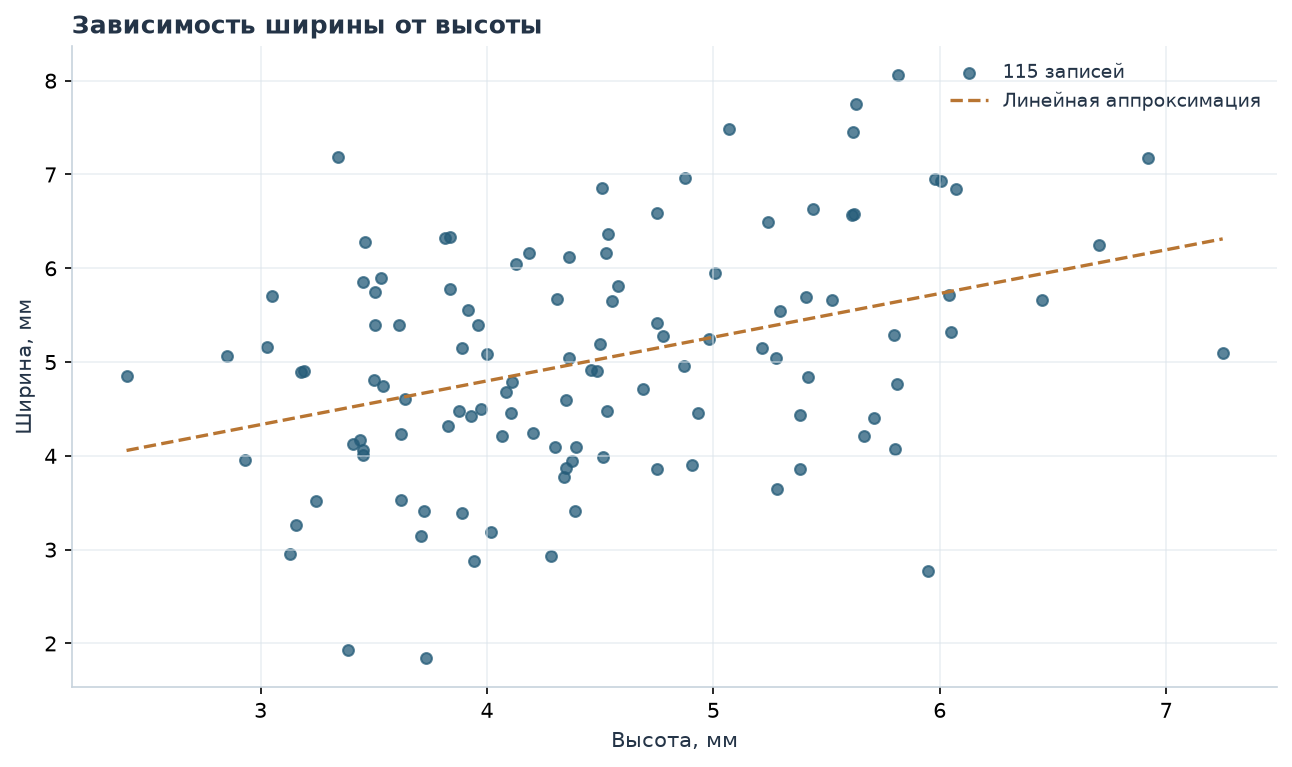

In [2]:
scatter_figure, scatter_axes = plt.subplots(figsize=(8.5, 5), constrained_layout=True)
scatter_axes.scatter(glyphs.height_mm, glyphs.width_mm, color=COLORS['UJI'], s=27, alpha=.75,
                     label=str(len(glyphs)) + ' записей')
regression_grid = np.linspace(glyphs.height_mm.min(), glyphs.height_mm.max(), 200)
scatter_axes.plot(regression_grid, ols_slope*regression_grid+ols_intercept, color=COLORS['UPV'],
                  linestyle='--', linewidth=1.6, label='Линейная аппроксимация')
scatter_axes.set(title='Зависимость ширины от высоты', xlabel='Высота, мм', ylabel='Ширина, мм')
scatter_axes.legend(fontsize=9)
finish_figure(scatter_figure, 'height-width.png')

Также определим корректность величины нашей выборки. Построим график зависимости среднего от размера выборки.

Максимальный размер здесь равен 115 — числу оставшихся записей. Для двух графиков использован один и тот же перемешанный порядок записей. Пунктиром отмечено среднее всего очищенного набора. При $n=115$ накопленное среднее совпадает с ним по построению; сам график не доказывает достаточность объёма выборки.

**Рисунок 2. Накопленное среднее высоты**

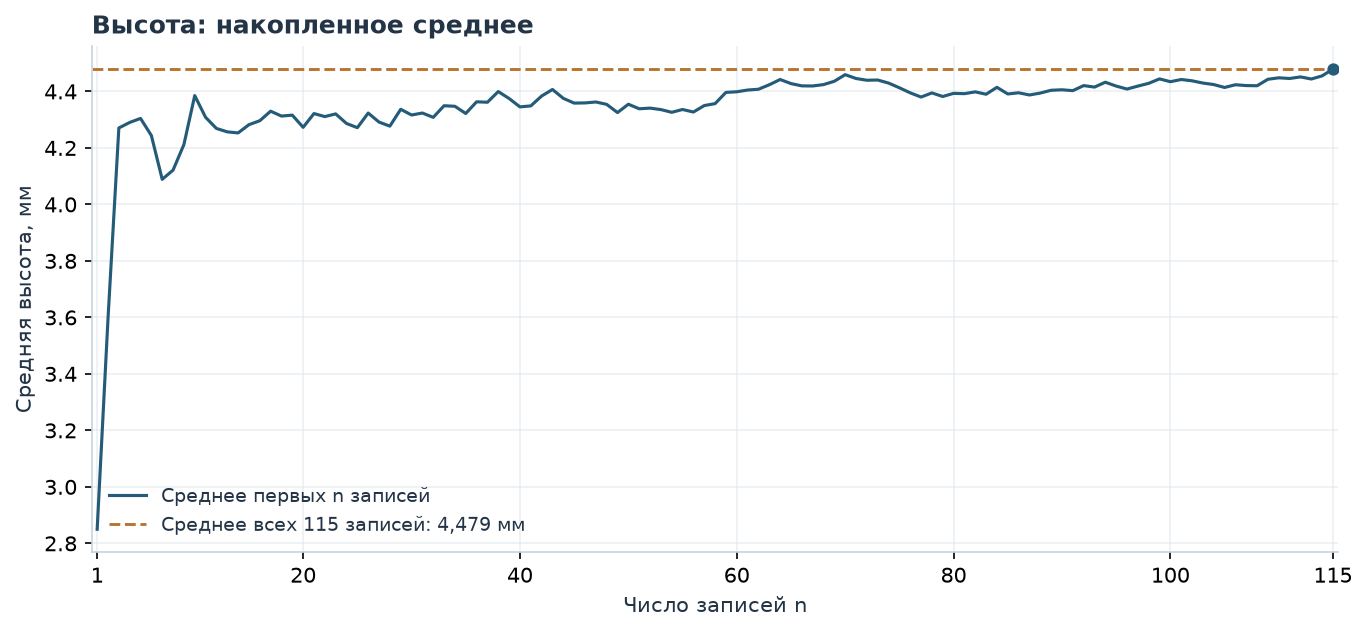

In [3]:
height_mean_artists = plot_cumulative('height_mm', 'Высота', 'height-mean.png')

**Рисунок 3. Накопленное среднее ширины**

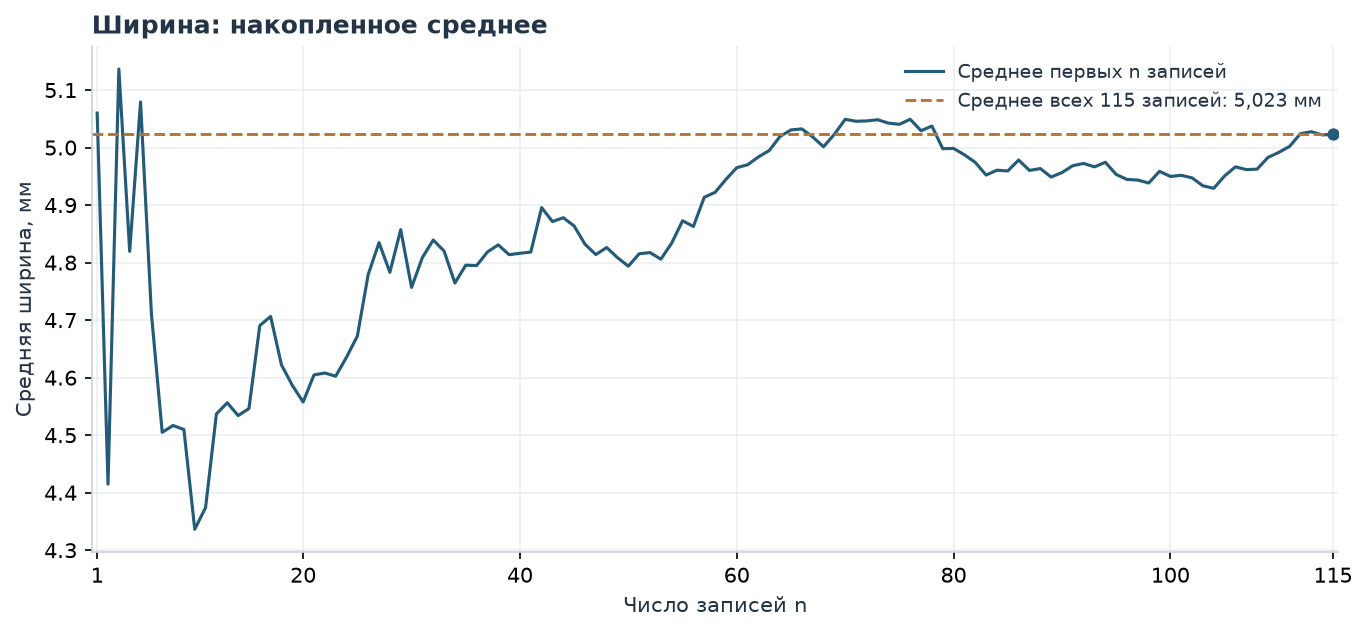

In [4]:
width_mean_artists = plot_cumulative('width_mm', 'Ширина', 'width-mean.png')

<a id="eda" name="eda"></a>

## EDA

### Высота

Средняя высота — 4,479 мм, медиана — 4,362 мм, стандартное отклонение — 0,974 мм. Ниже приведены остальные характеристики и распределение высоты.

**Таблица 1. Характеристики высоты**

In [5]:
display(pd.DataFrame([[r[0], r[2]] for r in statistic_rows(result, 'glyphs')],
    columns=['Показатель', 'Высота H']))

,Показатель,Высота H
0,"Объём, записей",115
1,"Сумма, мм","515,135"
2,"Среднее, мм","4,479"
3,"Медиана, мм","4,362"
4,"Минимум, мм","2,408"
5,"Максимум, мм","7,250"
6,"Стандартное отклонение, мм","0,974"
7,"Выборочная дисперсия, мм²","0,948"
8,"5-й перцентиль, мм","3,150"
9,"1-й квартиль, мм","3,727"


**Рисунок 4. Распределение высоты**

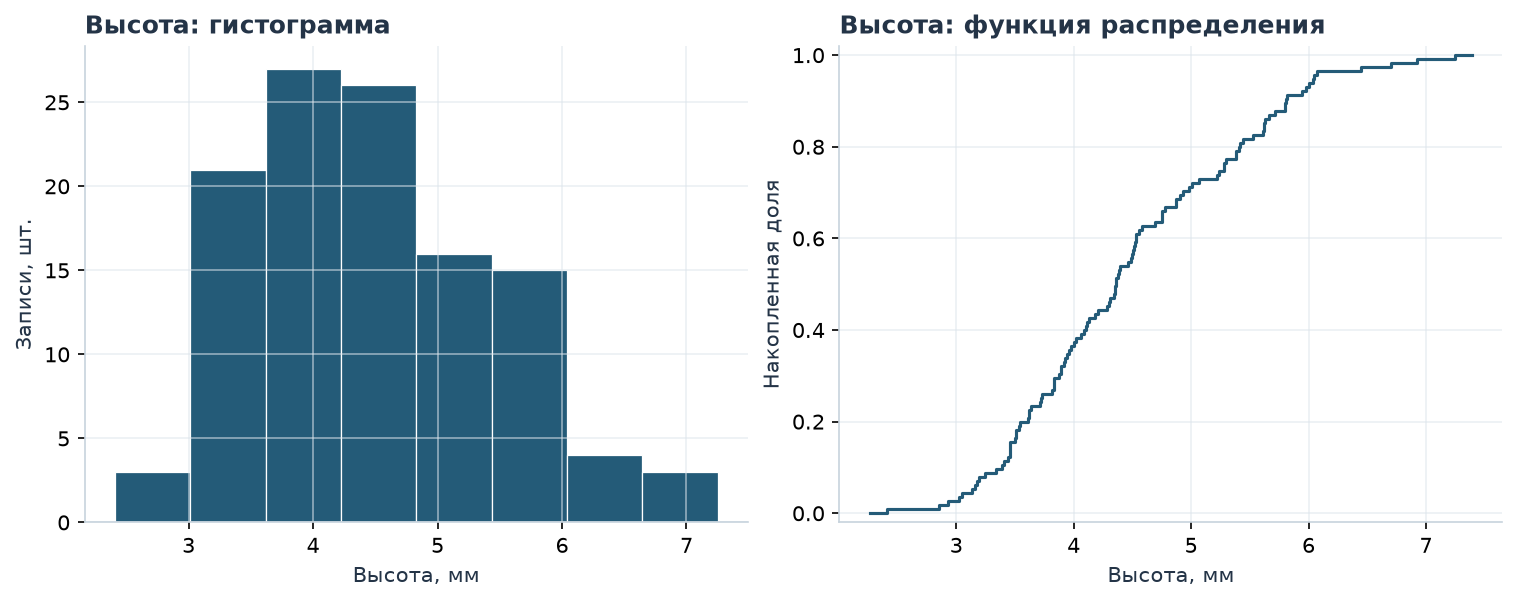

In [6]:
plot_distribution('height_mm', 'Высота', 'height-distribution.png')

### Ширина

Средняя ширина — 5,023 мм, медиана — 4,960 мм, стандартное отклонение — 1,238 мм. Ниже приведены остальные характеристики и распределение ширины.

**Таблица 2. Характеристики ширины**

In [7]:
display(pd.DataFrame([[r[0], r[1]] for r in statistic_rows(result, 'glyphs')],
    columns=['Показатель', 'Ширина W']))

,Показатель,Ширина W
0,"Объём, записей",115
1,"Сумма, мм","577,615"
2,"Среднее, мм","5,023"
3,"Медиана, мм","4,960"
4,"Минимум, мм","1,842"
5,"Максимум, мм","8,059"
6,"Стандартное отклонение, мм","1,238"
7,"Выборочная дисперсия, мм²","1,532"
8,"5-й перцентиль, мм","3,087"
9,"1-й квартиль, мм","4,145"


**Рисунок 5. Распределение ширины**

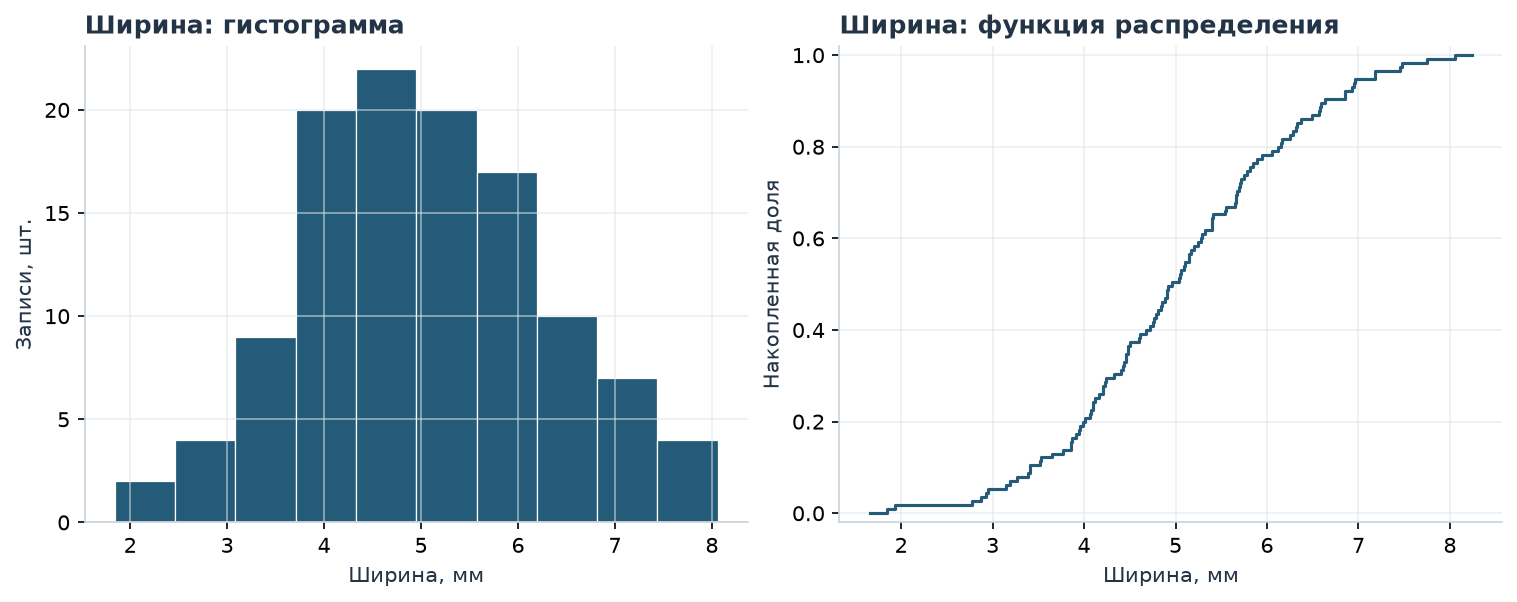

In [8]:
plot_distribution('width_mm', 'Ширина', 'width-distribution.png')

Для сравнения двух размеров записи упорядочены по ширине. Линия показывает ширину, точки — высоту той же записи. При равной ширине порядок задают автор и номер повторения; высоты отдельно не сортируются.

**Рисунок 6. Высота и ширина упорядоченных записей**

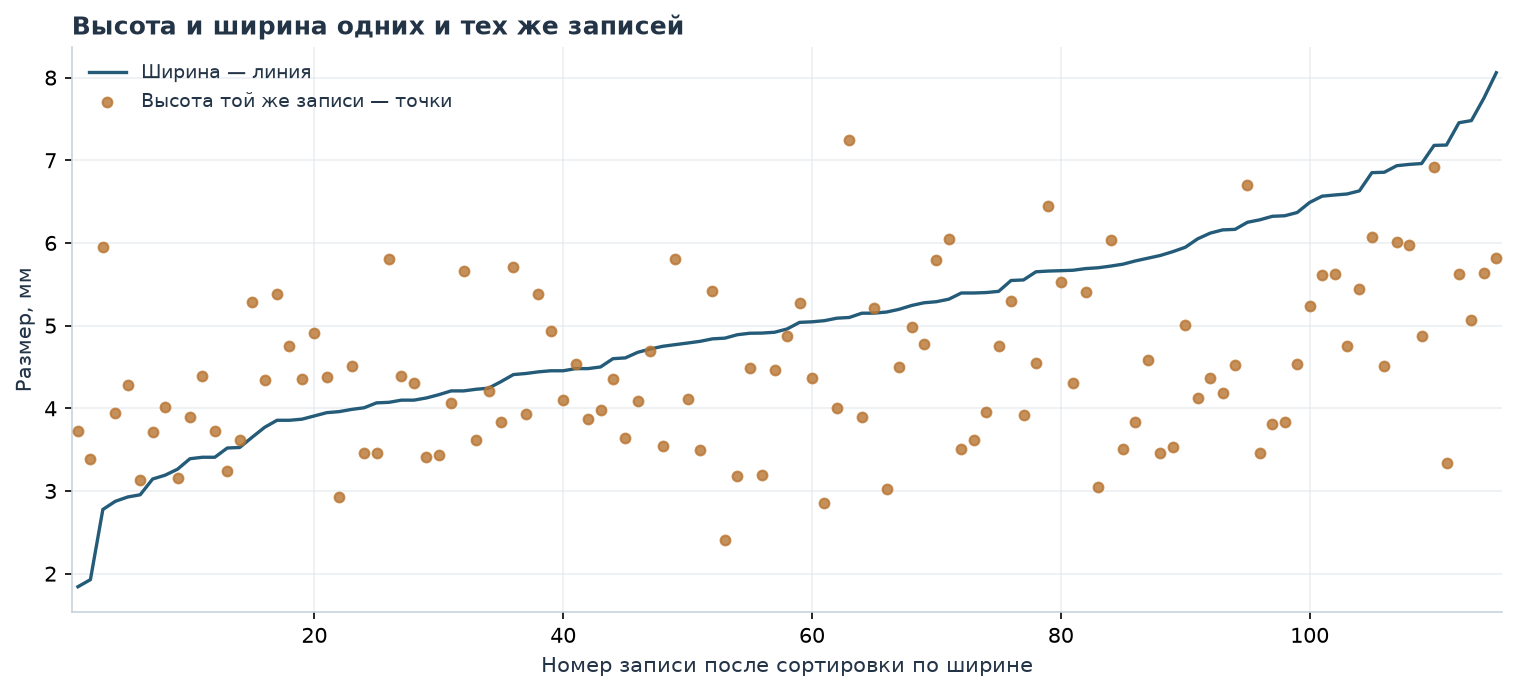

In [9]:
ordered_rank = np.arange(1, len(ordered)+1)
ordered_figure, ordered_axes = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ordered_width_line, = ordered_axes.plot(ordered_rank, ordered.width_mm, color=COLORS['UJI'],
                                       linewidth=1.6, label='Ширина — линия')
ordered_height_points = ordered_axes.scatter(ordered_rank, ordered.height_mm, color=COLORS['UPV'],
    s=22, alpha=.8, label='Высота той же записи — точки', zorder=3)
ordered_axes.set(title='Высота и ширина одних и тех же записей',
                  xlabel='Номер записи после сортировки по ширине', ylabel='Размер, мм',
                  xlim=(.5, len(ordered)+.5))
ordered_axes.legend(fontsize=9)
finish_figure(ordered_figure, 'ordered-pairs.png')

<a id="conclusion" name="conclusion"></a>

## Вывод

В очищенном наборе ширина в среднем больше высоты: 5,023 против 4,479 мм. Разброс ширины также больше: стандартное отклонение 1,238 против 0,974 мм. Статистически значимая ранговая связь с учётом площадки и числа повторов не подтвердилась. Утверждать независимость величин по этой проверке нельзя.

<a id="sources" name="sources"></a>

## Источники

1. [UJI Pen Characters (Version 2), UCI](https://archive.ics.uci.edu/dataset/177/uji+pen+characters+version+2), [DOI 10.24432/C5FG8S](https://doi.org/10.24432/C5FG8S), CC BY 4.0. Использованы записи латинской буквы a. В документации заданы масштабы 100 ink units/мм для UJI и 152 ink units/мм для UPV; размеры переведены в миллиметры экранной системы планшета.
2. Llorens D. et al. [The UJIpenchars Database: a Pen-Based Database of Isolated Handwritten Characters](https://aclanthology.org/L08-1467/), LREC, 2008.
3. [NIST: Box Plot](https://www.itl.nist.gov/div898/handbook/eda/section3/boxplot.htm) — правило границ Тьюки для обработки выбросов.
4. [SciPy: permutation_test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html) — перестановочная проверка и Monte Carlo поправка.

[Исходные измерения](data/glyphs.csv) · [Описание данных](data/provenance.json)